# Notebook 2 - Cluster Report
K-Means + Hierarchical clustering, cluster profiling, claim & premium behaviour.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
try: df = pd.read_csv("insurance.csv")
except FileNotFoundError: df = pd.read_csv(url)
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
# Clustering features: customer attributes only. 'charges' (cost) is the OUTCOME we analyse afterwards;
# 'region' is kept for profiling only (including it made clusters mere geographic splits).
X = pd.get_dummies(df.drop(columns=["charges","region"]), columns=["sex","smoker"], drop_first=True).astype(float)
Xs = StandardScaler().fit_transform(X)   # mandatory before PCA / K-Means
print(X.columns.tolist()); print(Xs.mean(0).round(2), Xs.std(0).round(2))

['age', 'bmi', 'children', 'sex_male', 'smoker_yes']
[-0. -0. -0. -0.  0.] [1. 1. 1. 1. 1.]


In [3]:
P=PCA(n_components=4).fit_transform(Xs); print(P.shape)

(1338, 4)


## 1. Elbow plot and silhouette scores

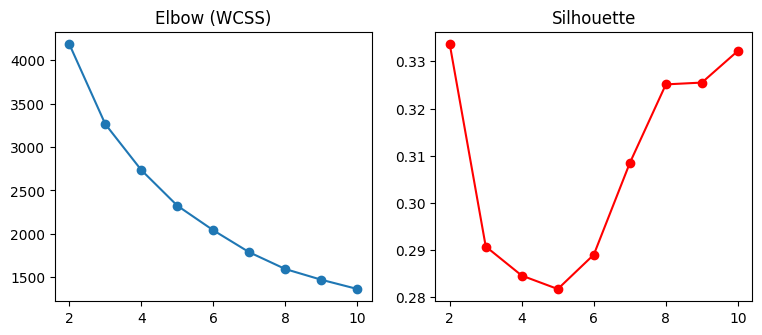

,K,WCSS,Silhouette
0,2,4188.5,0.334
1,3,3265.0,0.291
2,4,2735.1,0.285
3,5,2324.1,0.282
4,6,2039.9,0.289
5,7,1786.3,0.308
6,8,1593.1,0.325
7,9,1469.7,0.325
8,10,1363.1,0.332


In [4]:
ks=range(2,11); wcss=[];sil=[]
for k in ks:
    km=KMeans(k,n_init=10,random_state=42).fit(P); wcss.append(km.inertia_); sil.append(silhouette_score(P,km.labels_))
fig,a=plt.subplots(1,2,figsize=(9,3.5)); a[0].plot(ks,wcss,'o-'); a[0].set_title('Elbow (WCSS)'); a[1].plot(ks,sil,'o-',c='r'); a[1].set_title('Silhouette'); plt.show()
pd.DataFrame({'K':list(ks),'WCSS':np.round(wcss,1),'Silhouette':np.round(sil,3)})

Silhouette is highest at K=2 (a smoker / non-smoker split), but that is too coarse for business personas. **K=4** has a comparable silhouette (~0.28) and gives actionable segments, so K=4 is chosen.

## 2. Hierarchical clustering (Ward) + dendrogram

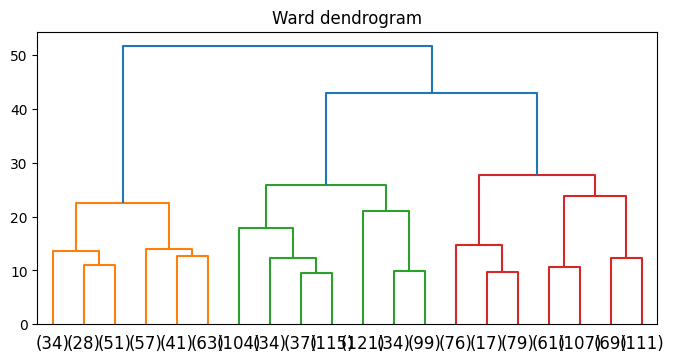

2 0.334
3 0.29
4 0.264
5 0.253
6 0.253


7 0.271
8 0.277


In [5]:
Z=linkage(P,'ward')
plt.figure(figsize=(8,3.8)); dendrogram(Z,truncate_mode='lastp',p=20); plt.title('Ward dendrogram'); plt.show()
for k in range(2,9): print(k, round(silhouette_score(P,AgglomerativeClustering(k,linkage='ward').fit_predict(P)),3))

## 3. Final model and label assignment

In [6]:
from sklearn.metrics import adjusted_rand_score
km=KMeans(4,n_init=10,random_state=42).fit(P); df['cluster']=km.labels_
hl=AgglomerativeClustering(4,linkage='ward').fit_predict(P)
print('Agreement K-Means vs Hierarchical (ARI):',round(adjusted_rand_score(km.labels_,hl),2))
df.head()

Agreement K-Means vs Hierarchical (ARI): 0.67


,age,sex,bmi,children,smoker,region,charges,cluster
0,19,female,27.900,0,yes,southwest,16884.92400,3
1,18,male,33.770,1,no,southeast,1725.55230,1
2,28,male,33.000,3,no,southeast,4449.46200,0
3,33,male,22.705,0,no,northwest,21984.47061,1
4,32,male,28.880,0,no,northwest,3866.85520,1


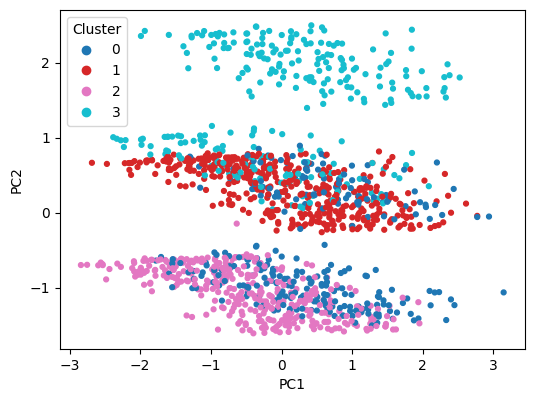

In [7]:
fig,ax=plt.subplots(figsize=(6,4.4)); sc=ax.scatter(P[:,0],P[:,1],c=km.labels_,cmap='tab10',s=12); ax.legend(*sc.legend_elements(),title='Cluster'); ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); plt.show()

## 4. Claim behaviour (severity)
The dataset has one cost column (`charges`); it has **no claim-count field**, so claim *frequency* cannot be measured. Severity is analysed via cost mean/median/90th percentile.

In [8]:
df['smoker_b']=(df.smoker=='yes').astype(int); df['male_b']=(df.sex=='male').astype(int)
g=df.groupby('cluster').agg(n=('age','size'),age=('age','mean'),bmi=('bmi','mean'),children=('children','mean'),smoker_pct=('smoker_b','mean'),male_pct=('male_b','mean'),mean_cost=('charges','mean'),median_cost=('charges','median'),p90=('charges',lambda s:s.quantile(.9)),total=('charges','sum')).round(2)
g['share_pop']=(g.n/len(df)).round(3); g['share_cost']=(g.total/df.charges.sum()).round(3); g

,n,age,bmi,children,smoker_pct,male_pct,mean_cost,median_cost,p90,total,share_pop,share_cost
cluster,,,,,,,,,,,,
0,276,41.62,30.30,2.77,0.0,0.35,10119.45,8610.76,15948.95,2792967.85,0.206,0.157
1,419,38.32,31.17,0.64,0.0,1.00,7659.31,6406.41,13598.02,3209250.16,0.313,0.181
2,370,38.93,30.29,0.36,0.0,0.00,8083.42,7046.11,13903.52,2990866.72,0.277,0.168
3,273,38.51,30.75,1.10,1.0,0.58,32097.95,34472.84,46648.98,8762740.26,0.204,0.494


## 5. Premium behaviour (scenario)
No premium column exists. **Scenario:** assume a one-size-fits-all premium equal to the portfolio mean cost. This shows cross-subsidy between clusters.

In [9]:
flat=df.charges.mean(); g['gap_vs_flat']=(g.mean_cost-flat).round(0); g['cost_to_flat_ratio']=(g.mean_cost/flat).round(2); print('flat premium',round(flat)); g[['n','mean_cost','gap_vs_flat','cost_to_flat_ratio']]

flat premium 13270


,n,mean_cost,gap_vs_flat,cost_to_flat_ratio
cluster,,,,
0,276,10119.45,-3151.0,0.76
1,419,7659.31,-5611.0,0.58
2,370,8083.42,-5187.0,0.61
3,273,32097.95,18828.0,2.42


In [10]:
pd.crosstab(df.cluster,df.region,normalize='index').round(2)

region,northeast,northwest,southeast,southwest
cluster,,,,
0,0.26,0.26,0.22,0.26
1,0.22,0.27,0.27,0.24
2,0.25,0.23,0.26,0.26
3,0.25,0.21,0.33,0.21
